# GL (G-mode + Lloyd) μ*=0.1 optimization runs — set C (Ti Nb Zr Hf Ta Mo W Y)

Runs in `opt.ratios.gl/sra.TiNbZrHfTaMoWY.*` (Topola, 2026-11), init database
`databases/sra.TiNbZrHfTaMoWY.kp10.ew0.6.gl.csv` (1200 random compositions computed from scratch for set C:
600 interior + 600 on faces/edges; 1179 usable).

* target `Tc_mu0.1` (McMillan, μ* = 0.1), θ_D = mixture Debye, no V/Sc corrections (set C has neither V nor Sc),
  Stoner penalty off, β = 2, `max_composition = 0.7`, `champions_per_step = 10`;
* **mincomp series** `mincomp2..8` (8 elements, so 9 and 10 do not exist) — sections 1–9;
* **comparison with the set A and set B runs** (same settings and target, set B without corr) — section 10.

Thermodynamics (bcc/fcc/hcp, ΔH) of the C champions has not been computed yet.

A composition *counts* for a run only if it has ≥ N elements with fraction > 0.05 (rule of `utils.log_iteration_summary`).
KKR results are read straight from `iteration_*/computation.tar` (`--pack_iterations`); no unpacking needed.
The last iteration of runs that were still running when copied has an empty `computation/` and is skipped.

In [1]:
from pathlib import Path
import json, re, tarfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = Path('../opt.ratios.gl')
TARGET = 'Tc_mu0.1'
RATIO = 0.05
ELEMENTS = ['Ti', 'Nb', 'Zr', 'Hf', 'Ta', 'Mo', 'W', 'Y']
EL_ALL = ['Ti', 'Nb', 'Zr', 'Hf', 'Ta', 'Mo', 'W', 'Y', 'Re', 'Ru', 'V', 'Sc']
EL_COLORS = dict(zip(EL_ALL, list(plt.cm.tab10.colors) + ['#444444', '#bbbbbb']))
pd.set_option('display.width', 250, 'display.max_columns', 40)

In [2]:
def parse_name(name):
    return {el: float(x) for el, x in re.findall(r'([A-Z][a-z]?)(\d+\.\d+)', name)}


def n_comp(row):
    return int(sum(row.get(el, 0.0) > RATIO for el in EL_ALL))


def comp_str(row, thr=0.005):
    parts = [(el, row[el]) for el in EL_ALL if row.get(el, 0.0) > thr]
    return ' '.join(f'{el}{100*v:.0f}' for el, v in sorted(parts, key=lambda p: -p[1]))


def iter_results(it_dir):
    # yields (results, selection_info) from computation.tar or from unpacked computation/
    tf = it_dir / 'computation.tar'
    if tf.exists():
        with tarfile.open(tf) as t:
            sel, res = {}, {}
            for m in t.getmembers():
                key = m.name.rstrip('/').split('/')[-2] if '/' in m.name.rstrip('/') else None
                if m.name.endswith('results.json'):
                    res[key] = json.load(t.extractfile(m))
                elif m.name.endswith('selection_info.json'):
                    sel[key] = json.load(t.extractfile(m))
            for k, r in res.items():
                yield r, sel.get(k, {})
        return
    for c in (it_dir / 'computation').glob('*'):
        rf, sf = c / 'results.json', c / 'selection_info.json'
        if rf.exists():
            yield json.loads(rf.read_text()), (json.loads(sf.read_text()) if sf.exists() else {})


def load_run(run_dir, target, elements=None):
    elements = elements or ELEMENTS
    params = json.loads((run_dir / 'parameters.json').read_text())
    mc = params['min_components']
    beta = float(params.get('acquisition_beta', np.nan))
    interior = '.interior.' in run_dir.name

    init = pd.read_csv(run_dir / 'init_tc_comparison.csv')
    comps = pd.DataFrame([parse_name(n) for n in init['name']]).reindex(columns=elements).fillna(0.0)
    init = pd.concat([comps, init[[f'{target}_computed']].rename(columns={f'{target}_computed': 'Tc'})], axis=1)
    init['iteration'] = 0
    init['source'] = 'init'

    rows = []
    for it_dir in run_dir.glob('iteration_*'):
        it = int(it_dir.name.split('_')[1])
        for r, s in iter_results(it_dir):
            row = {el: r.get(el, 0.0) for el in elements}
            row.update(iteration=it, source=s.get('source', '?'), Tc=r.get(target),
                       lam=r.get('lambda'), theta=r.get('thetaDB_K'), eta=r.get('eta_mix'), VEC=r.get('VEC'),
                       pred=s.get('pred_target'), pred_std=s.get('pred_target_std'),
                       dist=s.get('composition_distance'))
            rows.append(row)
    opt = pd.DataFrame(rows).sort_values('iteration').reset_index(drop=True)

    df = pd.concat([init, opt], ignore_index=True)
    df['n_comp'] = df.apply(n_comp, axis=1)
    df['valid'] = df['n_comp'] >= mc
    df['comp'] = df.apply(comp_str, axis=1)
    df['mincomp'] = mc
    df['acqbeta'] = beta
    label = f'mc{mc}' + (' int' if interior else '') + ('' if beta == 2 else f' β={beta:g}')
    df['run'] = label

    log = (run_dir / 'optimization_log.txt').read_text()
    m = re.search(r'EARLY STOP after iteration (\d+)', log)
    status = f'early stop @ {m.group(1)}' if m else 'no early stop (still running)'
    n_done = int(opt['iteration'].nunique())
    gaps = sorted(set(range(1, int(opt['iteration'].max()) + 1)) - set(opt['iteration'].unique()))
    if gaps:
        status += f', iteration(s) {gaps} lost (OOM before the fix)'
    return dict(mc=mc, beta=beta, interior=interior, label=label, params=params, df=df,
                status=status, n_iter=int(opt['iteration'].max()), n_done=n_done)


runs_all = sorted((load_run(d, TARGET) for d in BASE.glob('sra.TiNbZrHfTaMoWY.kp10*mincomp*') if d.is_dir()),
                  key=lambda r: (r['interior'], r['mc'], r['beta']))
runs = [r for r in runs_all if r['beta'] == 2 and not r['interior']]       # mincomp series
ALL = pd.concat([r['df'] for r in runs], ignore_index=True)
for r in runs_all:
    d = r['df']
    print(f"{r['label']:>14}: init={int((d.iteration==0).sum())} (valid {int(((d.iteration==0)&d.valid).sum())}), "
          f"opt={int((d.iteration>0).sum())}, iterations done={r['n_done']} (last {r['n_iter']}), {r['status']}")

           mc2: init=1109 (valid 1109), opt=198, iterations done=20 (last 20), early stop @ 20
           mc3: init=1109 (valid 1069), opt=240, iterations done=24 (last 24), early stop @ 24
           mc4: init=1109 (valid 969), opt=230, iterations done=23 (last 23), early stop @ 23
           mc5: init=1109 (valid 796), opt=320, iterations done=32 (last 32), early stop @ 32
           mc6: init=1109 (valid 512), opt=250, iterations done=25 (last 25), early stop @ 25
           mc7: init=1109 (valid 212), opt=190, iterations done=19 (last 19), early stop @ 19
           mc8: init=1109 (valid 9), opt=330, iterations done=33 (last 33), early stop @ 33


## 1. Summary table — best valid composition per run (mincomp series, β = 2)

In [3]:
def summary(rs, key='mincomp'):
    out = []
    for r in rs:
        d = r['df']; v = d[d.valid]
        i0, io = v[v.iteration == 0], v[v.iteration > 0]
        best = v.loc[v.Tc.idxmax()]
        out.append({key: r['mc'] if key == 'mincomp' else r[key], 'iters': r['n_done'], 'status': r['status'],
                    'n_init_valid': len(i0), 'init_best': i0.Tc.max(), 'opt_best': io.Tc.max(),
                    'gain_K': io.Tc.max() - i0.Tc.max(), 'best_iter': int(best.iteration),
                    'frac_new_valid': d[d.iteration > 0].valid.mean(),
                    'champion': best.comp, 'n_el': int(best.n_comp),
                    'lam': best.lam, 'theta': best.theta, 'VEC': best.VEC})
    return pd.DataFrame(out).set_index(key)

FMT = {'init_best': '{:.2f}', 'opt_best': '{:.2f}', 'gain_K': '{:+.2f}', 'frac_new_valid': '{:.0%}',
       'lam': '{:.2f}', 'theta': '{:.0f}', 'VEC': '{:.2f}'}
summ = summary(runs)
summ.style.format(FMT, na_rep='—')

,iters,status,n_init_valid,init_best,opt_best,gain_K,best_iter,frac_new_valid,champion,n_el,lam,theta,VEC
mincomp,,,,,,,,,,,,,
2,20,early stop @ 20,1109,17.61,18.98,+1.36,5,100%,Nb61 Zr39,2,1.14,273,4.61
3,24,early stop @ 24,1069,17.08,17.87,+0.80,9,100%,Nb59 Zr36 Ta5,3,1.10,271,4.64
4,23,early stop @ 23,969,14.12,16.63,+2.51,8,100%,Nb55 Zr35 Ta5 Hf5,4,1.05,270,4.60
5,32,early stop @ 32,796,10.87,15.18,+4.31,17,100%,Nb53 Zr32 Ti5 Ta5 Hf5,5,0.97,278,4.58
6,25,early stop @ 25,512,8.34,13.62,+5.28,10,100%,Nb61 Zr19 Y5 Ta5 Hf5 Ti5,6,0.90,279,4.60
7,19,early stop @ 19,212,6.03,11.89,+5.86,4,100%,Nb58 Zr16 Hf5 Ta5 Mo5 Ti5 Y5,7,0.83,288,4.69
8,33,early stop @ 33,9,2.63,9.57,+6.94,18,100%,Nb37 Zr32 Ti5 W5 Hf5 Y5 Ta5 Mo5,8,0.74,294,4.58


## 2. Convergence — best-so-far (valid only) and all new points per iteration

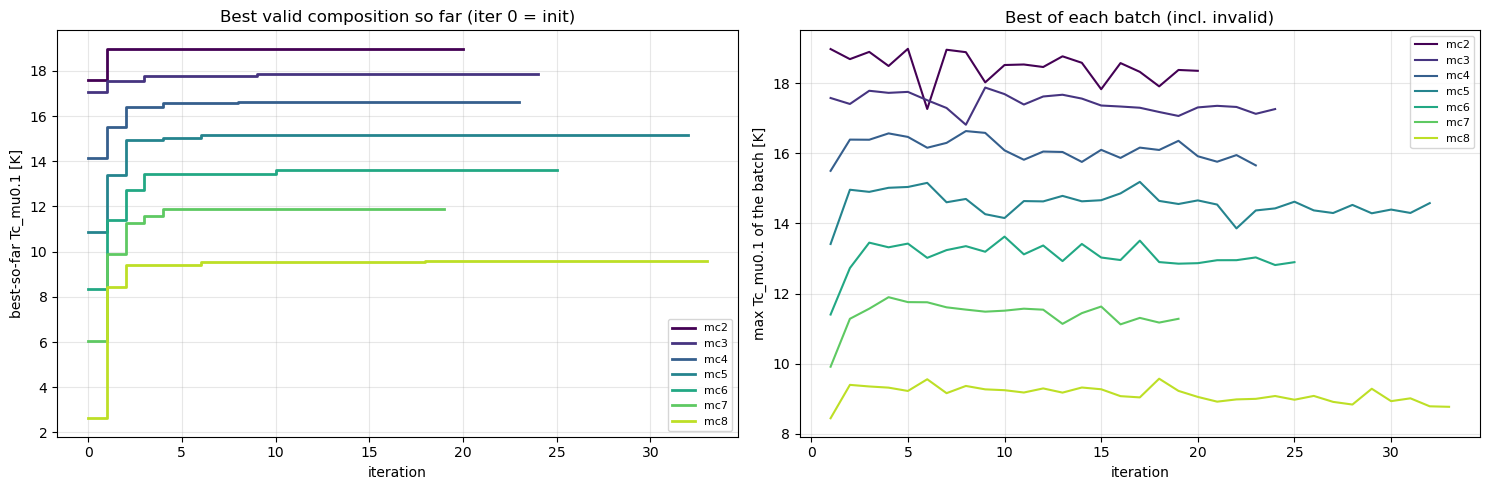

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
cmap = plt.cm.viridis(np.linspace(0, 0.9, len(runs)))
for r, c in zip(runs, cmap):
    d = r['df']; v = d[d.valid]
    its = np.arange(0, r['n_iter'] + 1)
    ax[0].step(its, [v[v.iteration <= i].Tc.max() for i in its], where='post', color=c, lw=2, label=r['label'])
    io = d[d.iteration > 0]
    ax[1].plot(io.groupby('iteration').Tc.max(), color=c, lw=1.5, label=r['label'])
ax[0].set(xlabel='iteration', ylabel=f'best-so-far {TARGET} [K]', title='Best valid composition so far (iter 0 = init)')
ax[1].set(xlabel='iteration', ylabel=f'max {TARGET} of the batch [K]', title='Best of each batch (incl. invalid)')
for a in ax:
    a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

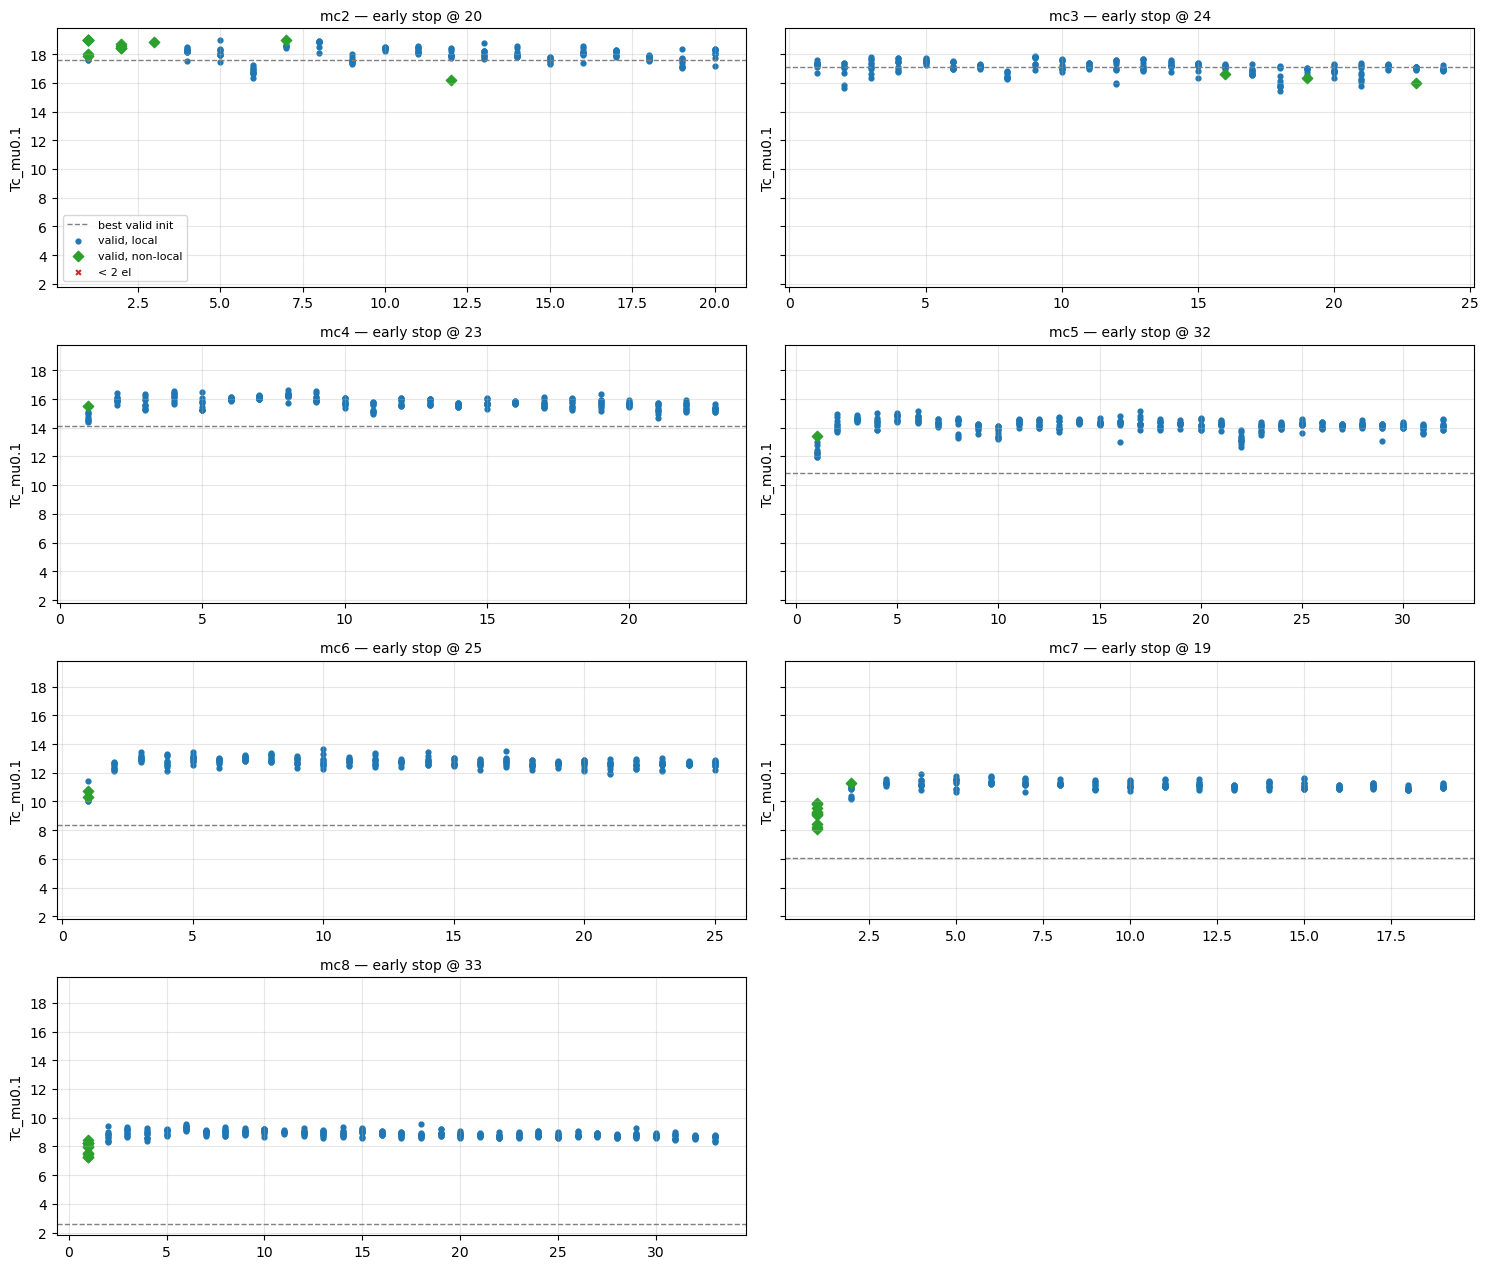

In [5]:
def scatter_runs(rs, title_key='label'):
    n = len(rs)
    fig, axes = plt.subplots((n + 1) // 2, 2, figsize=(15, 3.2 * ((n + 1) // 2)), sharey=True, squeeze=False)
    for a, r in zip(axes.flat, rs):
        d = r['df']; io = d[d.iteration > 0]
        a.axhline(d[(d.iteration == 0) & d.valid].Tc.max(), color='gray', ls='--', lw=1, label='best valid init')
        loc = io.source == 'local'
        a.scatter(io[io.valid & loc].iteration, io[io.valid & loc].Tc, s=12, c='C0', label='valid, local')
        a.scatter(io[io.valid & ~loc].iteration, io[io.valid & ~loc].Tc, s=28, c='C2', marker='D', label='valid, non-local')
        a.scatter(io[~io.valid].iteration, io[~io.valid].Tc, s=12, c='C3', marker='x', label=f"< {r['mc']} el")
        a.set_title(f"{r[title_key]} — {r['status']}", fontsize=10); a.grid(alpha=.3); a.set_ylabel(TARGET)
    axes.flat[0].legend(fontsize=8)
    for a in list(axes.flat)[n:]:
        a.axis('off')
    plt.tight_layout(); plt.show()

scatter_runs(runs)

## 3. Composition of the evaluated batches — mean element fraction per iteration

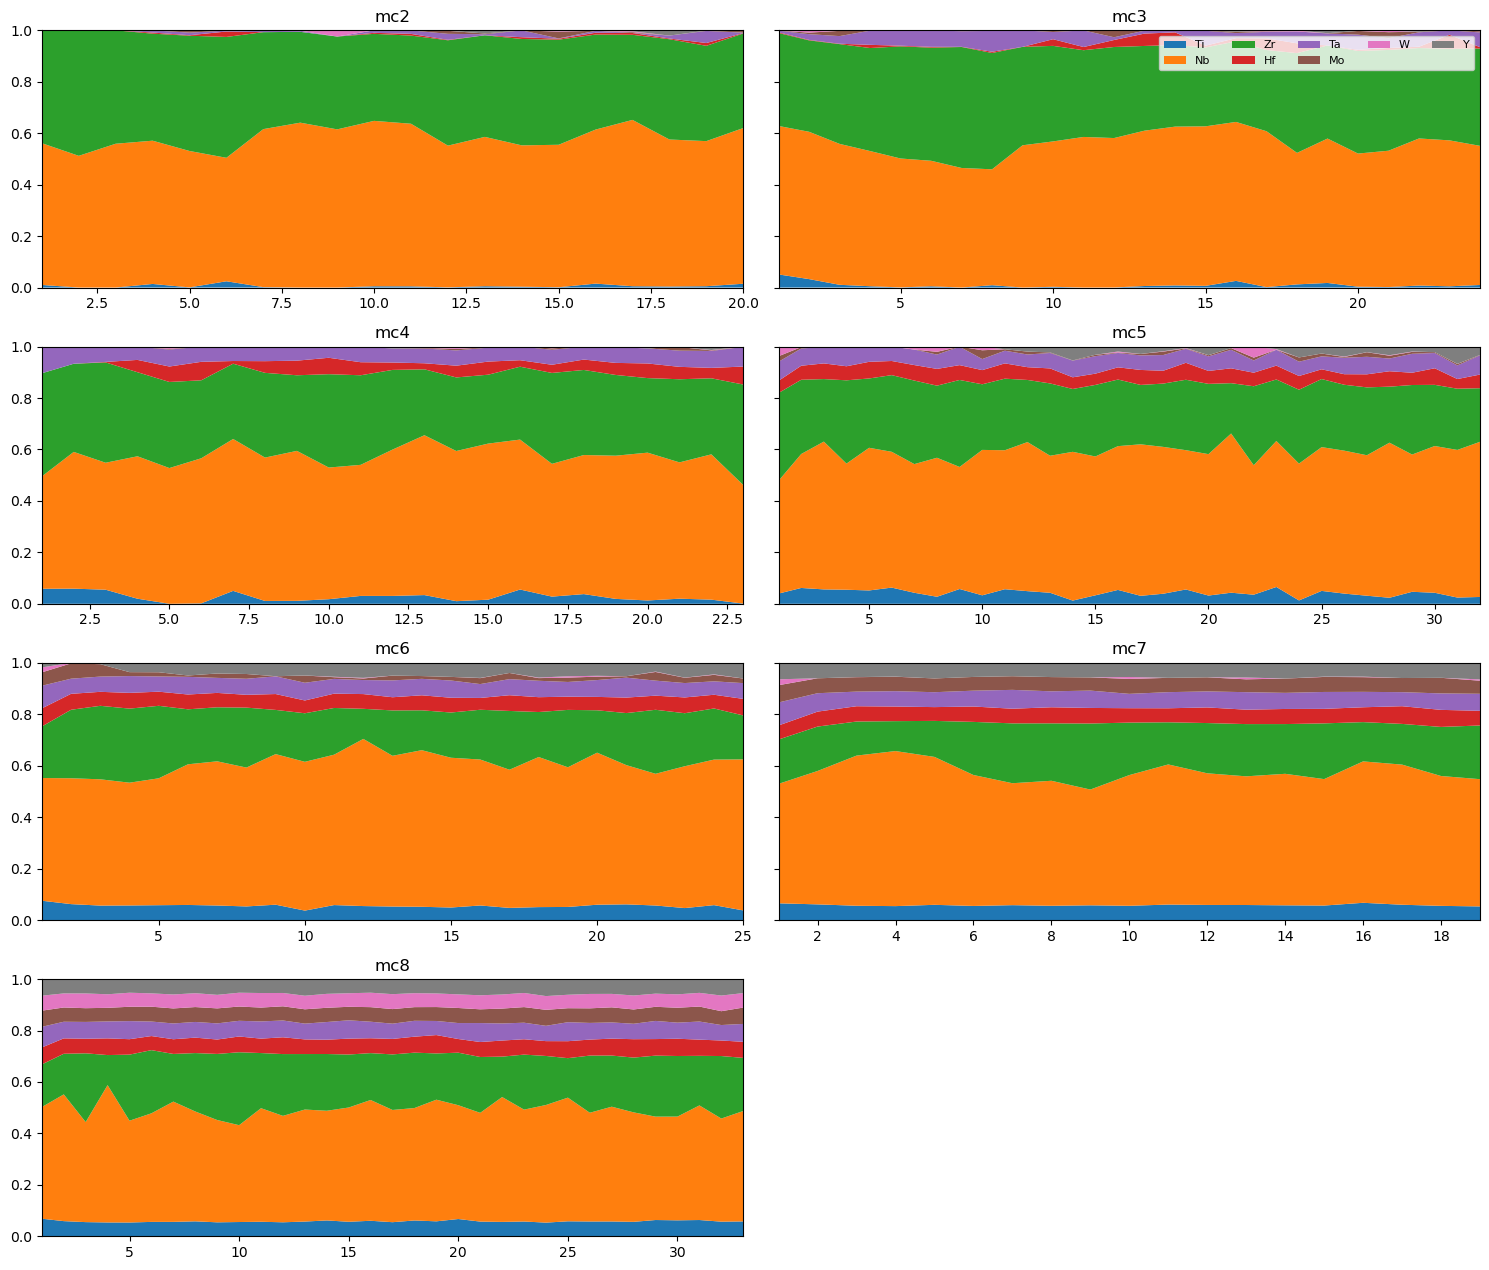

In [6]:
def stack_runs(rs):
    n = len(rs)
    fig, axes = plt.subplots((n + 1) // 2, 2, figsize=(15, 3.2 * ((n + 1) // 2)), sharey=True, squeeze=False)
    for a, r in zip(axes.flat, rs):
        io = r['df'][r['df'].iteration > 0]
        m = io.groupby('iteration')[ELEMENTS].mean()
        a.stackplot(m.index, m.T.values, labels=ELEMENTS, colors=[EL_COLORS[e] for e in ELEMENTS])
        a.set(xlim=(m.index.min(), m.index.max()), ylim=(0, 1), title=r['label'])
    axes.flat[min(1, n - 1)].legend(ncol=5, fontsize=8, loc='upper right')
    for a in list(axes.flat)[n:]:
        a.axis('off')
    plt.tight_layout(); plt.show()

stack_runs(runs)

## 4. Champions — top-5 valid compositions per run

mincomp,iteration,source,Tc,lam,theta,VEC,n_comp,comp
2,5,local,18.98,1.14,273,4.61,2,Nb61 Zr39
2,1,face,18.97,1.14,273,4.59,2,Nb59 Zr41
2,1,face,18.96,1.14,273,4.59,2,Nb59 Zr41
2,1,face,18.96,1.14,273,4.59,2,Nb59 Zr41
2,1,face,18.96,1.14,273,4.59,2,Nb59 Zr41
3,9,local,17.87,1.10,271,4.64,3,Nb59 Zr36 Ta5
3,9,local,17.82,1.09,271,4.63,3,Nb58 Zr37 Ta5
3,9,local,17.82,1.09,271,4.63,3,Nb58 Zr37 Ta5
3,9,local,17.79,1.09,271,4.64,3,Nb58 Zr36 Ta6
3,3,local,17.78,1.09,271,4.62,3,Nb56 Zr38 Ta6


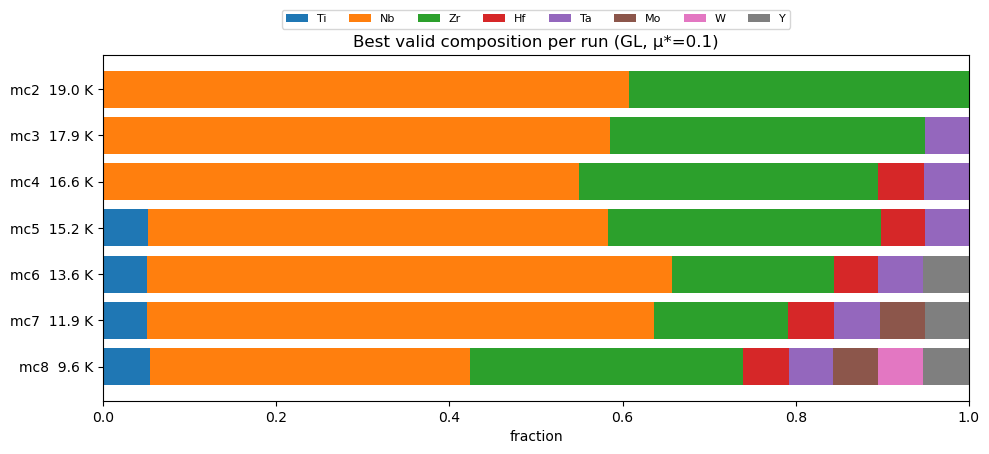

In [7]:
def champ_bar(champ, labels, title):
    fig, ax = plt.subplots(figsize=(10, 0.45 * len(champ) + 1.5))
    left = np.zeros(len(champ))
    for el in ELEMENTS:
        ax.barh(labels, champ[el], left=left, color=EL_COLORS[el], label=el)
        left += champ[el].values
    ax.set(xlabel='fraction', title=title); ax.invert_yaxis()
    ax.legend(ncol=12, fontsize=8, loc='lower center', bbox_to_anchor=(.5, 1.06))
    plt.tight_layout(); plt.show()

top = (ALL[ALL.valid].sort_values('Tc', ascending=False)
       .groupby('mincomp').head(5).sort_values(['mincomp', 'Tc'], ascending=[True, False]))
display(top[['mincomp', 'iteration', 'source', 'Tc', 'lam', 'theta', 'VEC', 'n_comp', 'comp']]
        .style.format({'Tc': '{:.2f}', 'lam': '{:.2f}', 'theta': '{:.0f}', 'VEC': '{:.2f}'}, na_rep='—').hide(axis='index'))
champ = ALL[ALL.valid].loc[lambda x: x.groupby('mincomp').Tc.idxmax()].set_index('mincomp')
champ_bar(champ, [f'mc{i}  {t:.1f} K' for i, t in zip(champ.index, champ.Tc)], 'Best valid composition per run (GL, μ*=0.1)')

## 5. Pareto front: best Tc vs. number of elements

All evaluated compositions of the mincomp series pooled (same pipeline/target), counting elements with fraction > 0.05.

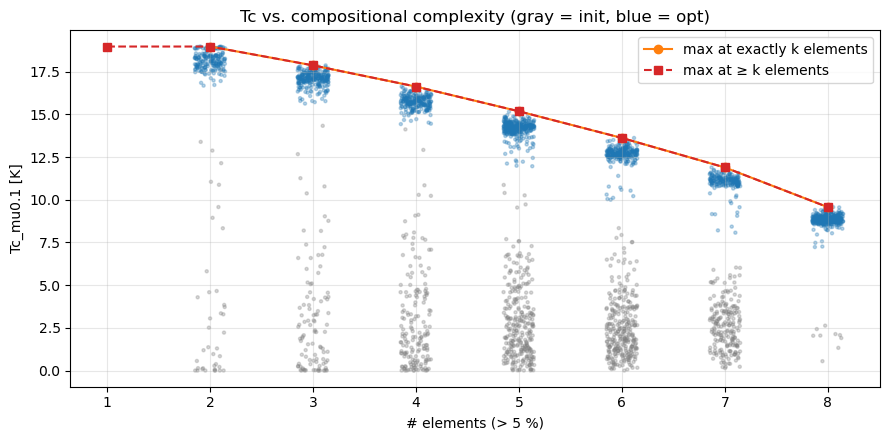

,1,2,3,4,5,6,7,8
best Tc at ≥ k elements,18.98,18.98,17.87,16.63,15.18,13.62,11.89,9.57


In [8]:
U = ALL.drop_duplicates(subset=ELEMENTS)
front = U.groupby('n_comp').Tc.max()
front_ge = pd.Series({k: U[U.n_comp >= k].Tc.max() for k in range(1, len(ELEMENTS) + 1)})
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(U.n_comp + np.random.default_rng(0).uniform(-.15, .15, len(U)), U.Tc, s=5, alpha=.3,
           c=np.where(U.iteration > 0, 'C0', 'gray'))
ax.plot(front.index, front.values, 'o-', c='C1', label='max at exactly k elements')
ax.plot(front_ge.index, front_ge.values, 's--', c='C3', label='max at ≥ k elements')
ax.set(xlabel='# elements (> 5 %)', ylabel=f'{TARGET} [K]', title='Tc vs. compositional complexity (gray = init, blue = opt)')
ax.grid(alpha=.3); ax.legend(); plt.tight_layout(); plt.show()
front_ge.rename('best Tc at ≥ k elements').to_frame().T.round(2)

## 6. Physics of the champions: λ vs θ_D, λ vs VEC

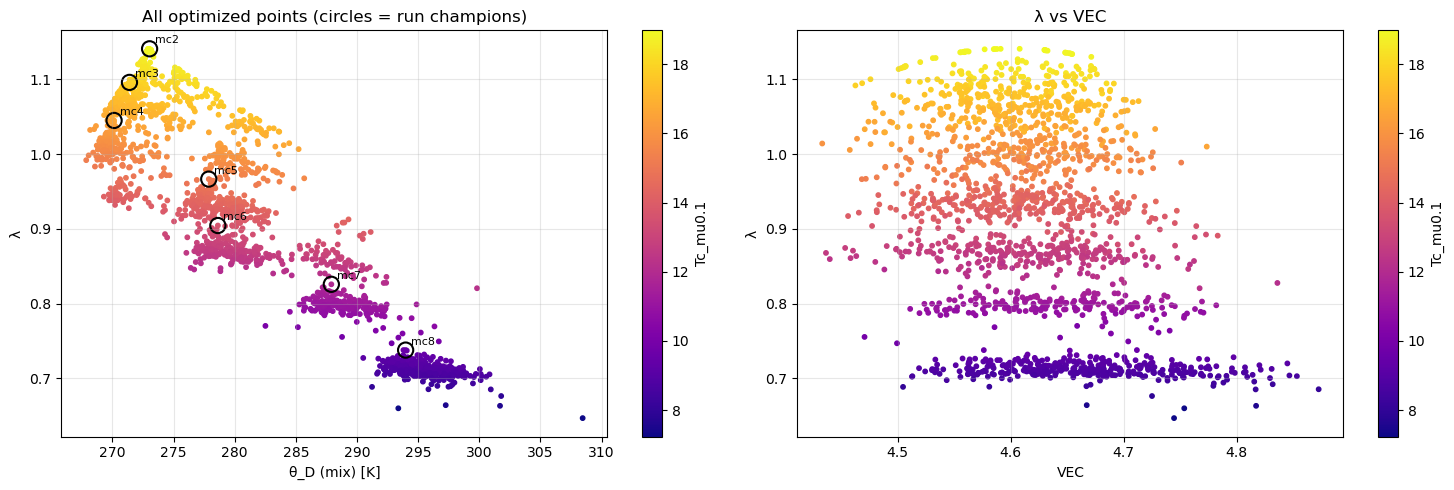

corr(λ, Tc) = 0.998,  corr(θ_D, Tc) = -0.886


In [9]:
O = ALL[ALL.iteration > 0]
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sc = ax[0].scatter(O.theta, O.lam, c=O.Tc, s=10, cmap='plasma')
ax[0].scatter(champ.theta, champ.lam, s=120, facecolor='none', edgecolor='k', lw=1.5)
for mc, row in champ.iterrows():
    ax[0].annotate(f'mc{mc}', (row.theta, row.lam), fontsize=8, xytext=(4, 4), textcoords='offset points')
plt.colorbar(sc, ax=ax[0], label=TARGET)
ax[0].set(xlabel='θ_D (mix) [K]', ylabel='λ', title='All optimized points (circles = run champions)')
sc = ax[1].scatter(O.VEC, O.lam, c=O.Tc, s=10, cmap='plasma')
plt.colorbar(sc, ax=ax[1], label=TARGET)
ax[1].set(xlabel='VEC', ylabel='λ', title='λ vs VEC')
for a in ax:
    a.grid(alpha=.3)
plt.tight_layout(); plt.show()
print(f"corr(λ, Tc) = {O[['lam', 'Tc']].corr().iloc[0, 1]:.3f},  corr(θ_D, Tc) = {O[['theta', 'Tc']].corr().iloc[0, 1]:.3f}")

## 7. Surrogate quality — CatBoost prediction (at selection) vs KKR result

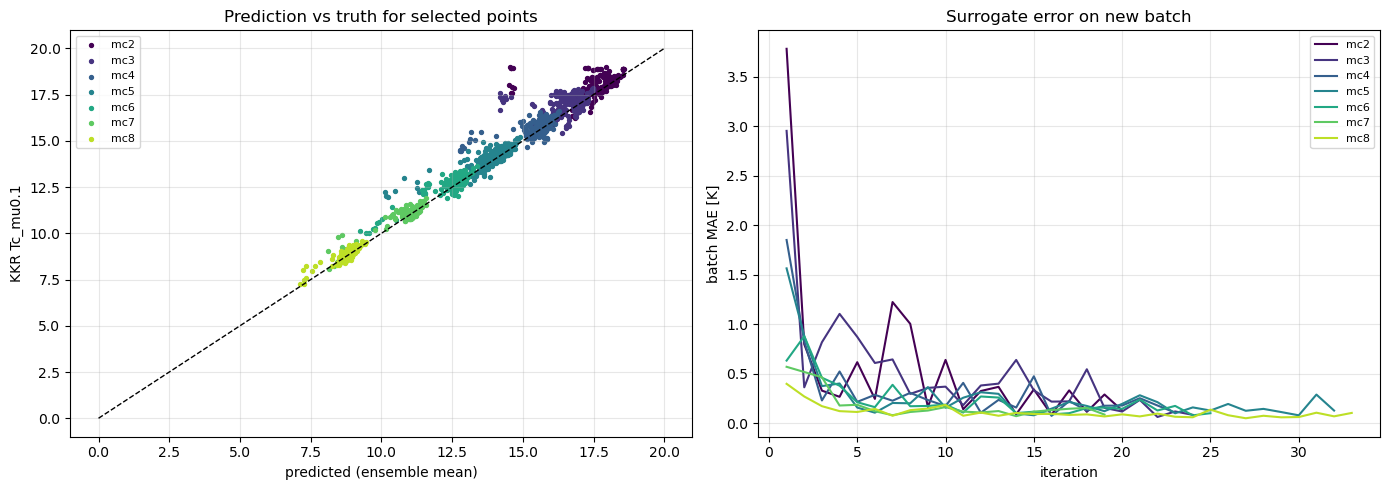

,n,MAE,bias,mean_std,within_1sigma,within_2sigma
label,,,,,,
mc2,198,0.563214,0.491330,0.696939,72%,100%
mc3,240,0.503234,0.392521,0.599092,71%,98%
mc4,230,0.329429,0.201984,0.416296,69%,93%
mc5,320,0.258512,0.150222,0.329846,70%,94%
mc6,250,0.234949,0.115708,0.249299,59%,92%
mc7,190,0.188623,0.082810,0.205362,61%,91%
mc8,330,0.111666,0.014010,0.148799,70%,94%


In [10]:
def surrogate(rs, key='label'):
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    out = []
    cm = plt.cm.viridis(np.linspace(0, 0.9, len(rs)))
    for r, c in zip(rs, cm):
        io = r['df'][(r['df'].iteration > 0) & r['df'].pred.notna()]
        err = io.Tc - io.pred; z = err / io.pred_std
        ax[0].scatter(io.pred, io.Tc, s=8, color=c, label=r[key])
        out.append({key: r[key], 'n': len(io), 'MAE': err.abs().mean(), 'bias': err.mean(),
                    'mean_std': io.pred_std.mean(), 'within_1sigma': (z.abs() < 1).mean(), 'within_2sigma': (z.abs() < 2).mean()})
        ax[1].plot(io.assign(ae=err.abs()).groupby('iteration').ae.mean(), color=c, label=r[key])
    lim = [0, max(r['df'].Tc.max() for r in rs) + 1]
    ax[0].plot(lim, lim, 'k--', lw=1)
    ax[0].set(xlabel='predicted (ensemble mean)', ylabel=f'KKR {TARGET}', title='Prediction vs truth for selected points')
    ax[1].set(xlabel='iteration', ylabel='batch MAE [K]', title='Surrogate error on new batch')
    for a in ax:
        a.grid(alpha=.3); a.legend(fontsize=8)
    plt.tight_layout(); plt.show()
    return (pd.DataFrame(out).set_index(key).style.format('{:.2f}')
            .format({'n': '{:d}', 'within_1sigma': '{:.0%}', 'within_2sigma': '{:.0%}'}))

surrogate(runs)

## 8. Where did the selected points come from? (acquisition source)

In [11]:
src = ALL[ALL.iteration > 0].groupby(['mincomp', 'source']).size().unstack(fill_value=0)
src.assign(champion_source=ALL[ALL.valid & (ALL.iteration > 0)].loc[lambda x: x.groupby('mincomp').Tc.idxmax()]
           .set_index('mincomp').source)

source,face,global,local,champion_source
mincomp,,,,
2,14,0,184,local
3,3,0,237,local
4,1,0,229,local
5,0,1,319,local
6,1,1,248,local
7,2,9,179,local
8,4,6,320,local


## 9. Distance travelled from the best init composition

Euclidean distance in composition space between each run's champion and its best valid init point.

In [12]:
def travel(rs):
    out = []
    for r in rs:
        v = r['df'][r['df'].valid]
        b0 = v[v.iteration == 0].loc[lambda x: x.Tc.idxmax()]
        b = v.loc[v.Tc.idxmax()]
        out.append(dict(run=r['label'], init_best=b0.comp, init_Tc=b0.Tc, champion=b.comp, champ_Tc=b.Tc,
                        distance=float(np.linalg.norm(b[ELEMENTS].values.astype(float) - b0[ELEMENTS].values.astype(float)))))
    return pd.DataFrame(out).set_index('run').round(3)

travel(runs)

,init_best,init_Tc,champion,champ_Tc,distance
run,,,,,
mc2,Zr55 Nb45,17.614,Nb61 Zr39,18.977,0.226
mc3,Nb58 Zr35 Ti7,17.076,Nb59 Zr36 Ta5,17.872,0.087
mc4,Zr41 Nb39 Ta14 Ti6,14.123,Nb55 Zr35 Ta5 Hf5,16.631,0.210
mc5,Nb63 Mo11 Zr10 Ti9 Y7,10.869,Nb53 Zr32 Ti5 Ta5 Hf5,15.183,0.278
mc6,Nb40 Zr21 Ta9 Mo9 Hf7 Ti6 Y4 W4,8.342,Nb61 Zr19 Y5 Ta5 Hf5 Ti5,13.622,0.236
mc7,Nb35 Ta21 Hf14 Ti8 W8 Y8 Zr6,6.033,Nb58 Zr16 Hf5 Ta5 Mo5 Ti5 Y5,11.895,0.326
mc8,Zr24 Y17 Ti15 Mo14 Hf8 W8 Nb7 Ta7,2.629,Nb37 Zr32 Ti5 W5 Hf5 Y5 Ta5 Mo5,9.571,0.355


## 10. Set C vs set A and set B — champions per mincomp

Same pipeline, target `Tc_mu0.1` and settings (β = 2, max 0.7); A adds Re and Ru, B adds V and Sc (here the B runs
**without** corr, so V–Ti/V-rich compositions can win). Set C is the common part of A and B.
If the C champions coincide with the A/B ones, the extra elements of A/B are irrelevant for the optimum.

In [13]:
SET_A = ['Ti', 'Nb', 'Zr', 'Hf', 'Ta', 'Mo', 'W', 'Y', 'Re', 'Ru']
SET_B = ['Ti', 'Nb', 'Zr', 'Hf', 'Ta', 'Mo', 'W', 'Y', 'V', 'Sc']
def load_set(pattern, els):
    rs = [load_run(d, TARGET, els) for d in BASE.glob(pattern) if d.is_dir()]
    rs = [r for r in rs if r['beta'] == 2 and not r['interior']]
    d = pd.concat([r['df'] for r in rs], ignore_index=True)
    for e in EL_ALL:
        if e not in d:
            d[e] = 0.0
    return d[d.valid].loc[lambda x: x.groupby('mincomp').Tc.idxmax()].set_index('mincomp')

champ_A = load_set('sra.TiNbZrHfTaMoWYReRu.kp10*.gl.mu0.1.acqbeta2.*mincomp*', SET_A)
champ_B = load_set('sra.TiNbZrHfTaMoWYVSc.kp10*.gl.mu0.1.acqbeta2.*mincomp*', SET_B)
champ_C = champ.copy()
for e in EL_ALL:
    if e not in champ_C:
        champ_C[e] = 0.0
dist = lambda a, b, m: float(np.linalg.norm(a.loc[m, EL_ALL].values.astype(float) - b.loc[m, EL_ALL].values.astype(float))) \
    if m in a.index and m in b.index else np.nan
cmpAB = pd.DataFrame({'Tc C': champ_C.Tc, 'Tc A': champ_A.Tc, 'Tc B (no corr)': champ_B.Tc,
                      'champion C': champ_C.comp, 'champion A': champ_A.comp, 'champion B': champ_B.comp})
cmpAB['dist C–A'] = [dist(champ_C, champ_A, m) for m in cmpAB.index]
cmpAB['dist C–B'] = [dist(champ_C, champ_B, m) for m in cmpAB.index]
cmpAB.style.format({'Tc C': '{:.2f}', 'Tc A': '{:.2f}', 'Tc B (no corr)': '{:.2f}', 'dist C–A': '{:.3f}', 'dist C–B': '{:.3f}'},
                   na_rep='—')

,Tc C,Tc A,Tc B (no corr),champion C,champion A,champion B,dist C–A,dist C–B
mincomp,,,,,,,,
2,18.98,18.99,20.14,Nb61 Zr39,Nb59 Zr41,V68 Ti32,0.020,1.043
3,17.87,17.92,17.90,Nb59 Zr36 Ta5,Nb56 Zr39 Ta5,Nb57 Zr38 Ta5,0.035,0.021
4,16.63,16.60,16.72,Nb55 Zr35 Ta5 Hf5,Nb56 Zr34 Hf5 Ta5,Nb52 Zr37 Ta5 V5,0.012,0.079
5,15.18,14.99,15.39,Nb53 Zr32 Ti5 Ta5 Hf5,Nb53 Zr31 Ta6 Ti5 Hf5,Nb51 Zr33 Ta5 Hf5 V5,0.012,0.076
6,13.62,13.52,14.08,Nb61 Zr19 Y5 Ta5 Hf5 Ti5,Nb47 Zr33 Ta5 Hf5 Mo5 Ti5,Nb55 Zr25 Ti6 Ta5 V5 Hf5,0.209,0.112
7,11.89,11.92,12.49,Nb58 Zr16 Hf5 Ta5 Mo5 Ti5 Y5,Nb53 Zr21 Y6 Ta5 Hf5 Ti5 Mo5,Nb62 Zr12 Ti6 Hf5 Ta5 Y5 V5,0.076,0.090
8,9.57,9.73,10.95,Nb37 Zr32 Ti5 W5 Hf5 Y5 Ta5 Mo5,Nb58 Y7 W7 Ta6 Zr6 Hf6 Ti5 Mo5,Nb62 Zr6 V6 Sc5 Ti5 Y5 Ta5 Hf5,0.335,0.377
9,—,7.22,9.41,—,Nb45 Zr14 Hf8 Ta7 Ti6 W5 Re5 Y5 Mo5,Nb57 Zr6 Y6 Sc6 Hf5 Ti5 V5 Mo5 Ta5,—,—
10,—,4.36,7.34,—,Zr41 Nb15 Ta6 Ti6 Hf6 Y5 Re5 Ru5 W5 Mo5,Nb40 Zr17 Ta6 Y6 Sc5 Hf5 V5 Ti5 W5 Mo5,—,—


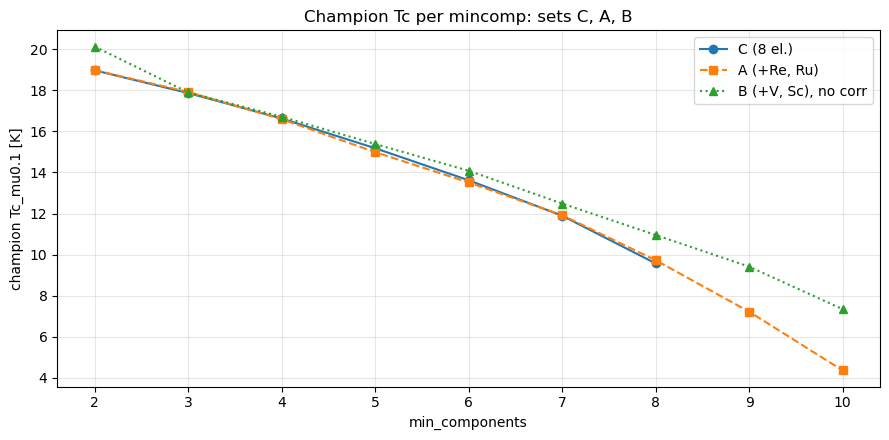

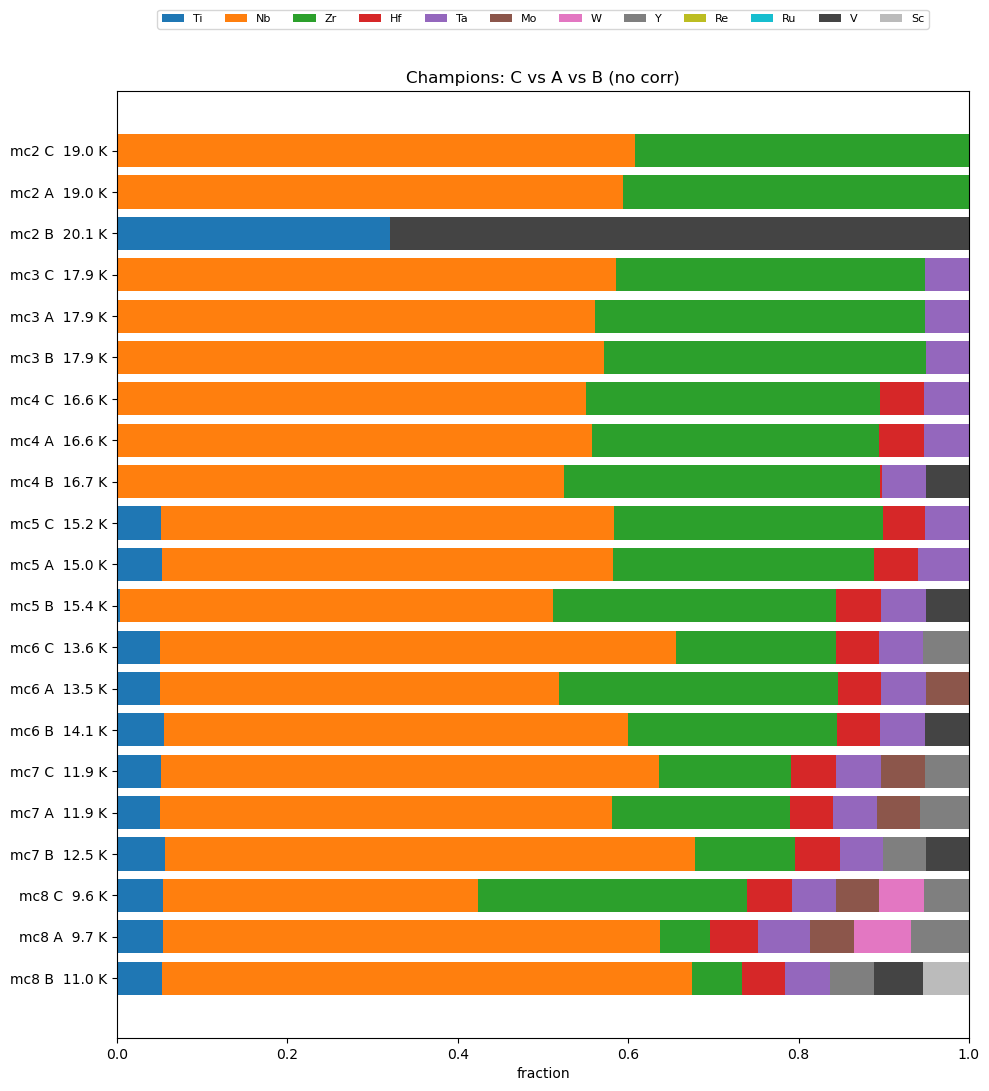

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for c, lab, m in [(champ_C, 'C (8 el.)', 'o-'), (champ_A, 'A (+Re, Ru)', 's--'), (champ_B, 'B (+V, Sc), no corr', '^:')]:
    ax.plot(c.index, c.Tc, m, label=lab)
ax.set(xlabel='min_components', ylabel=f'champion {TARGET} [K]', title='Champion Tc per mincomp: sets C, A, B')
ax.grid(alpha=.3); ax.legend(); plt.tight_layout(); plt.show()
both = pd.concat([champ_C.assign(set='C'), champ_A.assign(set='A'), champ_B.assign(set='B')]).reset_index()
both = both[both.mincomp <= 8].sort_values(['mincomp', 'set'], key=lambda s: s.map({'C': 0, 'A': 1, 'B': 2}) if s.name == 'set' else s)
ELEMENTS_BAR, ELEMENTS = ELEMENTS, EL_ALL
champ_bar(both.reset_index(drop=True), [f"mc{m} {s}  {t:.1f} K" for m, s, t in zip(both.mincomp, both.set, both.Tc)],
          'Champions: C vs A vs B (no corr)')
ELEMENTS = ELEMENTS_BAR

## 11. Conclusions (2026-11-20, all 7 runs early-stopped after 19–33 iterations)

**1. Same Nb–Zr basin as in sets A and B.** Champions: Nb61Zr39 (19.0 K), Nb59Zr36Ta5 (17.9), Nb55Zr35Ta5Hf5 (16.6),
Nb53Zr32 + Ti/Ta/Hf (15.2), mc6 13.6, mc7 11.9, mc8 9.6 K; VEC 4.58–4.69 in all runs. Forced elements sit at the 5 % floor
in the order Ta → Hf → Ti → Y/Mo → W.

**2. Set C reproduces the set A optimisation almost exactly, although its init data were computed independently.**
- Composition distance C–A is 0.01–0.04 for mc2–mc5 and mc7; Tc agrees within 0.2 K for every mincomp.
- mc6 (distance 0.21) and mc8 (0.34) differ only in the Nb/Zr ratio and in the 5 % element: the landscape is flat there.
  In mc8 the top 5 points span Nb37–48 within 0.2 K, and in mc6 the top 5 span Nb52–65 within 0.2 K.
- Re and Ru (set A) therefore play no role for k ≤ 8; their only effect is to fill the slots of mc9/mc10.

**3. Set B without corr differs only through V.** It wins mc2 with V68Ti32 (V overestimated, see the V correction) and
puts V into the 5 % slot for k ≥ 4, which raises Tc by 0.1–1.4 K. Everything else is the C/A family.

**4. The optimizer behaves as in A.**
- 97–100 % of the points come from `local`.
- The gain over the best init point grows with k: +1.4 K (mc2) to +6.9 K (mc8). For mc8 only 9 init points were valid.
- corr(λ, Tc) = 0.998, so the drop of Tc with k (19.0 → 9.6 K) comes entirely from λ (1.14 → 0.74); θ_D rises slightly
  (273 → 294 K).
- Surrogate bias is positive and decreases with k (+0.49 K mc2, +0.01 K mc8); 59–72 % of the points lie within 1σ.

**Bottom line.** The 8-element set C contains everything needed for the optimum. The A results do not depend on
Re/Ru and do not depend on the particular random init sample.